# Feature ablation study

- [Feature ablation study](#feature-ablation-study)
- [1. Data](#1-data)
- [2. Benchmark and ablation](#2-benchmark-and-ablation)
- [3. Feature importance table](#3-feature-importance-table)
- [4. Summary by group of features](#4-summary-by-group-of-features)
- [5. Importance by category of features](#5-importance-by-category-of-features)
- [6. DBSCAN clusters against the administrative zones](#6-dbscan-clusters-against-the-administrative-zones)

Written By: Keltonn [A0222591J]

AI Used: Claude Sonnet 5.5

**Question.** How much does each of the 329 model features (152 static + 177 temporal) contribute to predicting the rent, in a model where all the others are present?

**Experiment.** Run a single stage lasso regressor on all 329 features as the benchmark, then iteratively drop features to see the loss in RMSE. The larger the loss, the more important the feature.

1. The **benchmark** is the Lasso fitted on the train rows (2021-01..2024-03) with all 329 features, and scored on the train rows and on the validation rows (2024-04..2025-03).

2. For every feature, the **same Lasso is refitted without that feature** (the other 328 stay) and scored again.

3. The **loss** of a feature is the validation RMSE without it minus the benchmark validation RMSE: a positive loss means the model gets worse when the feature is removed (the feature is useful), a loss near zero that the other features already carry what it carries, a negative loss that the model is better without it.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 400)


import os, sys
from pathlib import Path
_here = Path(os.environ.get('RENT_PROJECT_ROOT') or Path.cwd()).resolve()
sys.path.insert(0, str(next(p for p in [_here, *_here.parents] if (p / 'data' / 'config.py').exists())))      # final_report: data/config.py holds every path
from data import config as cfg
ROOT = cfg.ROOT
from data.feature_config_static import CATEGORICAL_COL, HOT_COL, LABEL, NUMERICAL_COL      # noqa: E402
from data.feature_config_temporal import COE_FEATURE, MACRO_FEATURE, STOCK_FEATURE         # noqa: E402

FINAL = cfg.FINAL_DIR
RESULT_CSV = cfg.ABLATION_STUDY_CSV

ALPHA = 0.001            # the one Lasso setting (penalty on the standardised rent): small, so that the ablation measures the features, not the penalty
TOL = 1e-8               # convergence tolerance of the coordinate descent (the temporal features are strongly collinear, so a tight tolerance is needed)
RECOMPUTE = False        # True: run the 329 refits again and overwrite the csv

## 1. Data

- [Feature ablation study](#feature-ablation-study)
- [1. Data](#1-data)
- [2. Benchmark and ablation](#2-benchmark-and-ablation)
- [3. Feature importance table](#3-feature-importance-table)
- [4. Summary by group of features](#4-summary-by-group-of-features)
- [5. Importance by category of features](#5-importance-by-category-of-features)
- [6. DBSCAN clusters against the administrative zones](#6-dbscan-clusters-against-the-administrative-zones)

Load features, labels and perform standard scaling on the dataset

In [ ]:
STATIC = NUMERICAL_COL + CATEGORICAL_COL + HOT_COL
TEMPORAL = STOCK_FEATURE + COE_FEATURE + MACRO_FEATURE
FEATURES = STATIC + TEMPORAL
assert len(FEATURES) == 329 and len(set(FEATURES)) == 329

month_index = lambda year, month: (year - 2021) * 12 + month - 1
static = pd.read_csv(FINAL / 'static_train_scaled.csv')
static['month'] = month_index(static['RENT_APPROVAL_YEAR'], static['RENT_APPROVAL_MONTH'])
temporal = pd.read_csv(FINAL / 'temporal_scaled.csv')
temporal['month'] = month_index(temporal['RENT_APPROVAL_YEAR'], temporal['RENT_APPROVAL_MONTH'])
temporal = temporal.set_index('month')[TEMPORAL].fillna(0.0)

# Load Training Data
X = pd.concat([static[STATIC].reset_index(drop=True), temporal.loc[static['month']].reset_index(drop=True)], axis=1)       # one row per rental: its static features and the temporal features of its month
y = static[LABEL].to_numpy(float)
fit, val = (static['sample_type'] == 'train').to_numpy(), (static['sample_type'] == 'val').to_numpy()
assert not X.isna().any().any()

# Standard Scaling
values = X.to_numpy(float)
is_binary = np.array([set(np.unique(X[c])) <= {0.0, 1.0} for c in FEATURES])
centre, spread = values[fit].mean(axis=0), values[fit].std(axis=0)
scale = np.where(is_binary | (spread == 0), 1.0, spread)                      # 0/1 columns and constant columns are only centred
Z = (values - centre) / scale
Z_train, Z_val = Z[fit], Z[val]
y_mean, y_std = y[fit].mean(), y[fit].std()
y_train_std = (y[fit] - y_mean) / y_std
constant = [c for c in FEATURES if X.loc[fit, c].nunique() <= 1]
print(f'{len(FEATURES)} features ({len(STATIC)} static, {len(TEMPORAL)} temporal); train rows {fit.sum():,}, validation rows {val.sum():,}')
print(f'constant on the train rows (their removal changes nothing): {constant}')


def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))


def static_group(c):
    if c.startswith('plan_area_ft_'):
        return 'planning-area demographics'
    if c.startswith('dbscan_cluster_'):
        return 'location cluster (DBSCAN)'
    if c.startswith(('nearest_pri_school', 'pri_sch_')):
        return 'primary school'
    if c.startswith(('nearest_sec_school', 'sec_sch_')):
        return 'secondary school'
    if c.startswith(('nearest_jc_school', 'jc_')):
        return 'junior college'
    if c.startswith('nearest_school'):
        return 'nearest school (any level)'
    if c.startswith(('nearest_station', 'n_stations', 'mrt_traffic', 'train_lines', 'station_is_open')):
        return 'MRT'
    if c in ('n_malls_500m', 'nearest_mall_m'):
        return 'mall'
    return 'flat'


def temporal_group(c):
    if c in COE_FEATURE:
        return 'COE'
    if c in MACRO_FEATURE:
        return 'macro'
    return 'stock: log price' if c.endswith('_log_price_mean') else 'stock: monthly return' if c.endswith('_mom_return') else 'stock: volatility'


FEATURE_SET = {**{c: 'static' for c in STATIC}, **{c: 'temporal' for c in TEMPORAL}}
GROUP = {**{c: static_group(c) for c in STATIC}, **{c: temporal_group(c) for c in TEMPORAL}}

329 features (152 static, 177 temporal); train rows 114,841, validation rows 35,158
constant on the train rows (their removal changes nothing): ['station_is_open', 'FLAT_MODEL_improved maisonette']


## 2. Benchmark and ablation

- [Feature ablation study](#feature-ablation-study)
- [1. Data](#1-data)
- [2. Benchmark and ablation](#2-benchmark-and-ablation)
- [3. Feature importance table](#3-feature-importance-table)
- [4. Summary by group of features](#4-summary-by-group-of-features)
- [5. Importance by category of features](#5-importance-by-category-of-features)
- [6. DBSCAN clusters against the administrative zones](#6-dbscan-clusters-against-the-administrative-zones)

The Lasso is fitted from the Gram matrix of the standardised features (`precompute`): the coordinate descent then does not touch the 115,000 rows again, so a fit takes a fraction of a second instead of a minute, and gives the same solution.
Each ablation refits the Lasso on the remaining 328 columns (submatrix of the Gram matrix), starting from the benchmark coefficients, which makes the 329 refits quick.

In [3]:
def fit_lasso(keep, gram, start=None):
    """Lasso (no intercept: the columns and the rent are centred) of the standardised train rent on the columns `keep`."""
    model = Lasso(alpha=ALPHA, precompute=gram[np.ix_(keep, keep)], fit_intercept=False, warm_start=start is not None, max_iter=1_000_000, tol=TOL)
    if start is not None:
        model.coef_ = start[keep].copy()
    return model.fit(Z_train[:, keep], y_train_std)


def scores(model, keep):
    return (rmse(y[fit], model.predict(Z_train[:, keep]) * y_std + y_mean), rmse(y[val], model.predict(Z_val[:, keep]) * y_std + y_mean))


if RESULT_CSV.exists() and not RECOMPUTE:
    ablation = pd.read_csv(RESULT_CSV)
    print(f'loaded {len(ablation)} rows from {RESULT_CSV}')
else:
    started = time.time()
    gram = Z_train.T @ Z_train
    everything = np.ones(len(FEATURES), dtype=bool)
    benchmark = fit_lasso(everything, gram)
    bench_train, bench_val = scores(benchmark, everything)
    print(f'benchmark, all {len(FEATURES)} features (alpha {ALPHA}): train RMSE ${bench_train:,.2f}, validation RMSE ${bench_val:,.2f}, {int((benchmark.coef_ != 0).sum())} non-zero coefficients, {benchmark.n_iter_:,} iterations')
    rows = []
    for j, feature in enumerate(FEATURES):
        keep = everything.copy()
        keep[j] = False
        model = fit_lasso(keep, gram, start=benchmark.coef_)
        train_rmse, val_rmse = scores(model, keep)
        rows.append({'feature': feature, 'feature_set': FEATURE_SET[feature], 'group': GROUP[feature], 'constant_on_train': feature in constant, 'train_rmse': train_rmse, 'val_rmse': val_rmse,
                     'train_rmse_change': train_rmse - bench_train, 'val_rmse_loss': val_rmse - bench_val, 'val_rmse_loss_pct': 100 * (val_rmse - bench_val) / bench_val,
                     'in_benchmark_model': bool(benchmark.coef_[j] != 0), 'benchmark_train_rmse': bench_train, 'benchmark_val_rmse': bench_val})
    ablation = pd.DataFrame(rows).sort_values('val_rmse_loss', ascending=False).reset_index(drop=True)
    ablation.insert(0, 'rank', np.arange(1, len(ablation) + 1))
    RESULT_CSV.parent.mkdir(parents=True, exist_ok=True)
    ablation.to_csv(RESULT_CSV, index=False)
    print(f'{len(ablation)} refits in {time.time() - started:,.0f} s; saved to {RESULT_CSV}')

assert len(ablation) == len(FEATURES) and set(ablation['feature']) == set(FEATURES)
bench_train, bench_val = ablation['benchmark_train_rmse'].iloc[0], ablation['benchmark_val_rmse'].iloc[0]

loaded 329 rows from /Users/keltonn/Desktop/Repo/school/CS5228-project/final_report/01_data_processing/03_merge_all_features/result/ablation_study.csv


## 3. Feature importance table

- [Feature ablation study](#feature-ablation-study)
- [1. Data](#1-data)
- [2. Benchmark and ablation](#2-benchmark-and-ablation)
- [3. Feature importance table](#3-feature-importance-table)
- [4. Summary by group of features](#4-summary-by-group-of-features)
- [5. Importance by category of features](#5-importance-by-category-of-features)
- [6. DBSCAN clusters against the administrative zones](#6-dbscan-clusters-against-the-administrative-zones)

`val_rmse_loss` is the validation RMSE without the feature minus the benchmark validation RMSE (dollars; positive = the feature helps); `train_rmse_change` is the same for the train rows. `in_benchmark_model` says whether the benchmark Lasso gave the feature a non-zero coefficient (a feature the Lasso dropped by itself can only change the fit slightly when removed).
The full table of the 329 features, in the order of the loss, is `result/ablation_study.csv`; the 25 features whose removal costs the most, and the 25 whose removal helps the most, are shown here.

In [4]:
print(f'benchmark with all {len(ablation)} features: train RMSE ${bench_train:,.2f}, validation RMSE ${bench_val:,.2f}')
columns = ['rank', 'feature', 'group', 'train_rmse', 'val_rmse', 'train_rmse_change', 'val_rmse_loss', 'val_rmse_loss_pct', 'in_benchmark_model']
print('\nthe 25 features whose removal costs the most validation RMSE')
display(ablation[columns].head(25).round(2).set_index('rank'))
print('the 25 features whose removal improves the validation RMSE the most')
display(ablation[columns].tail(25).iloc[::-1].round(2).set_index('rank'))

benchmark with all 329 features: train RMSE $497.91, validation RMSE $502.78

the 25 features whose removal costs the most validation RMSE


,feature,group,train_rmse,val_rmse,train_rmse_change,val_rmse_loss,val_rmse_loss_pct,in_benchmark_model
rank,,,,,,,,
1,stk_wilmar_international_log_price_mean,stock: log price,497.91,512.69,-0.00,9.91,1.97,True
2,stk_singtel_log_price_mean,stock: log price,497.91,509.92,0.00,7.14,1.42,True
3,MACRO_SORA_3M_PCT,macro,497.91,508.99,0.00,6.21,1.23,True
4,MAX_FLOOR,flat,501.60,507.53,3.69,4.75,0.94,True
5,stk_mapletree_logistics_trust_log_price_mean,stock: log price,497.91,507.11,0.00,4.33,0.86,True
6,MACRO_UNEMPLOYMENT_SA_PCT,macro,497.91,504.79,0.00,2.01,0.40,True
7,stk_sheng_siong_group_log_price_mean,stock: log price,497.91,504.50,0.00,1.72,0.34,True
8,stk_ifast_corporation_return_volatility,stock: volatility,497.91,504.50,0.00,1.72,0.34,True
9,stk_cmon_log_price_mean,stock: log price,497.91,504.33,0.00,1.55,0.31,True


the 25 features whose removal improves the validation RMSE the most


,feature,group,train_rmse,val_rmse,train_rmse_change,val_rmse_loss,val_rmse_loss_pct,in_benchmark_model
rank,,,,,,,,
329,stk_capitaland_ascott_trust_log_price_mean,stock: log price,497.91,501.66,0.00,-1.12,-0.22,True
328,stk_singapore_post_log_price_mean,stock: log price,497.91,501.69,0.00,-1.09,-0.22,True
327,stk_sea_limited_log_price_mean,stock: log price,497.91,501.79,-0.00,-0.99,-0.20,True
326,stk_comfortdelgro_return_volatility,stock: volatility,497.91,501.93,0.00,-0.85,-0.17,True
325,stk_grab_holdings_log_price_mean,stock: log price,497.91,501.94,0.00,-0.84,-0.17,True
324,stk_jardine_cycle_carriage_return_volatility,stock: volatility,497.91,502.02,0.00,-0.76,-0.15,True
323,coe_c_quota_premium,COE,497.91,502.14,0.00,-0.64,-0.13,True
322,stk_mapletree_logistics_trust_return_volatility,stock: volatility,497.91,502.22,0.00,-0.56,-0.11,True
321,stk_hotel_properties_limited_mom_return,stock: monthly return,497.91,502.34,0.00,-0.45,-0.09,True


## 4. Summary by group of features

- [Feature ablation study](#feature-ablation-study)
- [1. Data](#1-data)
- [2. Benchmark and ablation](#2-benchmark-and-ablation)
- [3. Feature importance table](#3-feature-importance-table)
- [4. Summary by group of features](#4-summary-by-group-of-features)
- [5. Importance by category of features](#5-importance-by-category-of-features)
- [6. DBSCAN clusters against the administrative zones](#6-dbscan-clusters-against-the-administrative-zones)

In [5]:
by_group = ablation.groupby(['feature_set', 'group']).agg(features=('feature', 'size'), in_benchmark_model=('in_benchmark_model', 'sum'), mean_val_rmse_loss=('val_rmse_loss', 'mean'), max_val_rmse_loss=('val_rmse_loss', 'max'),
                                                            min_val_rmse_loss=('val_rmse_loss', 'min'), features_that_help=('val_rmse_loss', lambda s: int((s > 0.5).sum())), features_that_hurt=('val_rmse_loss', lambda s: int((s < -0.5).sum())))
display(by_group.sort_values('max_val_rmse_loss', ascending=False).round(2))
print(f'features whose removal costs more than $1 of validation RMSE: {int((ablation["val_rmse_loss"] > 1).sum())}; within +-$1: {int((ablation["val_rmse_loss"].abs() <= 1).sum())}; improves by more than $1: {int((ablation["val_rmse_loss"] < -1).sum())}')

features  in_benchmark_model  mean_val_rmse_loss  max_val_rmse_loss  min_val_rmse_loss  features_that_help  features_that_hurt
feature_set group                                                                                                                                                     
temporal    stock: log price                  53                  13                0.39               9.91              -1.12                   5                   4
            macro                              6                   2                1.37               6.21              -0.00                   2                   0
static      flat                              28                  12                0.29               4.75              -0.05                   5                   0
temporal    stock: volatility                 53                   7                0.04               1.72              -0.85                   4                   3
            stock: monthly return             53                   5                0.00               0.58              -0.45                   1                   0
static      MRT                               13                   7                0.04               0.45              -0.05                   0                   0
            location cluster (DBSCAN)         48                  14                0.01               0.19              -0.06                   0                   0
            junior college                    12                   5                0.02               0.14              -0.00                   0                   0
temporal    COE                               12                   3               -0.05               0.12              -0.64                   0                   1
static      mall                               2                   2                0.06               0.07               0.05                   0                   0
            planning-area demographics        16                   9               -0.00               0.05              -0.06                   0                   0
            primary school                     6                   3                0.01               0.03              -0.00                   0                   0
            secondary school                  11                   6               -0.00               0.03              -0.04                   0                   0
            nearest school (any level)        16                   3                0.00               0.02              -0.02                   0                   0

features whose removal costs more than $1 of validation RMSE: 10; within +-$1: 317; improves by more than $1: 2


The 20 features whose removal increases the validation RMSE the most, in the order of `val_rmse_loss` (the order of the csv). Blue bars are static features, orange bars temporal ones.

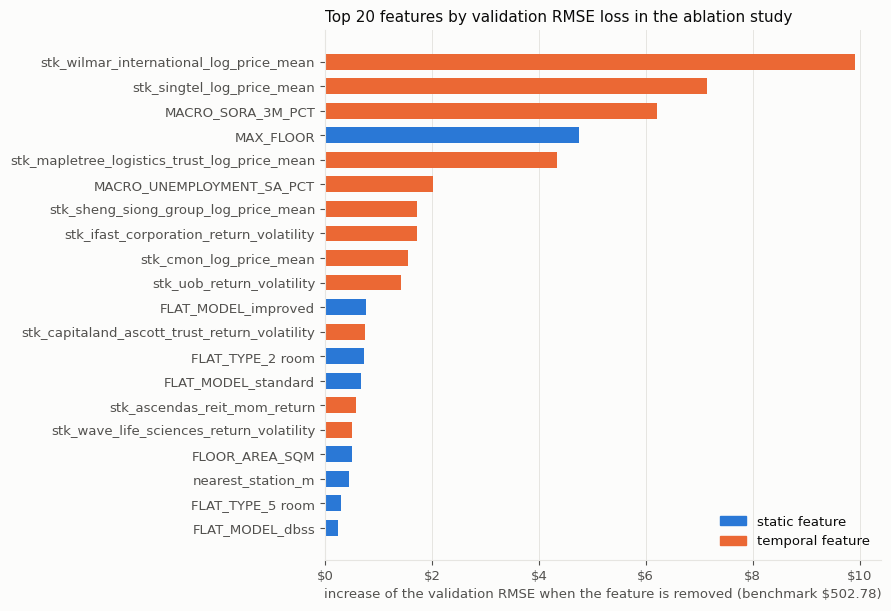

In [6]:
import matplotlib.pyplot as plt

assert ablation['val_rmse_loss'].is_monotonic_decreasing                       # the table is ordered by the validation loss
TOP = 20
top = ablation.head(TOP)
colours = {'static': '#2a78d6', 'temporal': '#eb6834'}
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#e6e5e1', 'axes.labelcolor': '#52514e', 'axes.titlecolor': '#0b0b0b', 'axes.titlesize': 11,
                     'axes.titleweight': 'normal', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.7,
                     'axes.axisbelow': True, 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'text.color': '#0b0b0b', 'font.size': 9.5, 'legend.frameon': False})
fig, ax = plt.subplots(figsize=(9, 6.2))
pos = np.arange(TOP)
ax.barh(pos, top['val_rmse_loss'], color=[colours[s] for s in top['feature_set']], height=0.65)
ax.set_yticks(pos, top['feature'])
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_xlabel(f'increase of the validation RMSE when the feature is removed (benchmark ${bench_val:,.2f})')
ax.set_title(f'Top {TOP} features by validation RMSE loss in the ablation study')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f'{s} feature') for s, c in colours.items()], loc='lower right')
plt.tight_layout()
plt.show()

## 5. Importance by category of features

- [Feature ablation study](#feature-ablation-study)
- [1. Data](#1-data)
- [2. Benchmark and ablation](#2-benchmark-and-ablation)
- [3. Feature importance table](#3-feature-importance-table)
- [4. Summary by group of features](#4-summary-by-group-of-features)
- [5. Importance by category of features](#5-importance-by-category-of-features)
- [6. DBSCAN clusters against the administrative zones](#6-dbscan-clusters-against-the-administrative-zones)

How much does each module of features matter? The single-feature losses of the ablation table are added up inside the categories of three splits:

1. **temporal against static** features;
2. the **static categories**: flat characteristics, planning-area demographics, DBSCAN location clusters, railway stations, malls and schools (the four school groups of the table are merged);
3. the **temporal categories**: stocks (price, return and volatility features), COE and the macroeconomy.

For each category the table gives the **sum of the validation RMSE losses** of its features (`sum_val_rmse_loss`, in dollars), split into the part contributed by features whose removal hurts (`sum_of_losses`) and by features whose removal helps (`sum_of_gains`), and the mean loss per feature.
**A sum of single-feature losses is not the loss of the category.** A feature that has a substitute costs almost nothing when it is removed alone, so the sum understates a module whose features replace one another, and positive and negative losses cancel. To check, the table also gives `category_removed_val_rmse_loss`: the loss in validation RMSE when **all the features of the category are removed at once** (the Lasso is refitted without them), which is what the module is worth to the model.
The result is saved to `result/ablation_by_category.csv` (and reloaded unless `RECOMPUTE = True`).

In [7]:
STATIC_CATEGORY = {'flat': 'flat characteristics', 'planning-area demographics': 'planning-area demographics', 'location cluster (DBSCAN)': 'DBSCAN clusters', 'MRT': 'railway stations', 'mall': 'malls',
                   'nearest school (any level)': 'schools', 'primary school': 'schools', 'secondary school': 'schools', 'junior college': 'schools'}
TEMPORAL_CATEGORY = {'stock: log price': 'stocks', 'stock: monthly return': 'stocks', 'stock: volatility': 'stocks', 'COE': 'COE', 'macro': 'macroeconomy'}
ablation['category'] = [STATIC_CATEGORY[g] if s == 'static' else TEMPORAL_CATEGORY[g] for g, s in zip(ablation['group'], ablation['feature_set'])]
SPLITS = {'temporal vs static': ablation['feature_set'], 'static categories': ablation['category'].where(ablation['feature_set'] == 'static'), 'temporal categories': ablation['category'].where(ablation['feature_set'] == 'temporal')}
CATEGORY_CSV = RESULT_CSV.parent / 'ablation_by_category.csv'

if CATEGORY_CSV.exists() and not RECOMPUTE:
    by_category = pd.read_csv(CATEGORY_CSV)
    print(f'loaded {len(by_category)} rows from {CATEGORY_CSV}')
else:
    gram = Z_train.T @ Z_train
    everything = np.ones(len(FEATURES), dtype=bool)
    benchmark = fit_lasso(everything, gram)
    position = {f: i for i, f in enumerate(FEATURES)}
    rows = []
    for split, labels in SPLITS.items():
        for category in labels.dropna().unique():
            members = ablation.loc[labels == category]
            keep = everything.copy()
            keep[[position[f] for f in members['feature']]] = False
            model = fit_lasso(keep, gram, start=benchmark.coef_)
            train_rmse, val_rmse = scores(model, keep)
            loss = members['val_rmse_loss']
            rows.append({'split': split, 'category': category, 'features': len(members), 'features_in_benchmark_model': int(members['in_benchmark_model'].sum()), 'sum_val_rmse_loss': loss.sum(),
                         'sum_of_losses': loss[loss > 0].sum(), 'sum_of_gains': loss[loss < 0].sum(), 'mean_loss_per_feature': loss.mean(), 'category_removed_val_rmse': val_rmse,
                         'category_removed_val_rmse_loss': val_rmse - bench_val, 'category_removed_train_rmse_change': train_rmse - bench_train})
    by_category = pd.DataFrame(rows).sort_values(['split', 'sum_val_rmse_loss'], ascending=[True, False]).reset_index(drop=True)
    by_category.to_csv(CATEGORY_CSV, index=False)
    print(f'saved {len(by_category)} rows to {CATEGORY_CSV}')

print(f'benchmark with all {len(FEATURES)} features: validation RMSE ${bench_val:,.2f}')
for split in SPLITS:
    print(f'\n{split}')
    display(by_category[by_category['split'] == split].drop(columns='split').set_index('category').round(2))

loaded 11 rows from /Users/keltonn/Desktop/Repo/school/CS5228-project/final_report/01_data_processing/03_merge_all_features/result/ablation_by_category.csv
benchmark with all 329 features: validation RMSE $502.78

temporal vs static


,features,features_in_benchmark_model,sum_val_rmse_loss,sum_of_losses,sum_of_gains,mean_loss_per_feature,category_removed_val_rmse,category_removed_val_rmse_loss,category_removed_train_rmse_change
category,,,,,,,,,
temporal,177,30,30.42,38.45,-8.03,0.17,735.65,232.87,149.77
static,152,61,9.79,10.23,-0.45,0.06,660.75,157.97,106.52



static categories


,features,features_in_benchmark_model,sum_val_rmse_loss,sum_of_losses,sum_of_gains,mean_loss_per_feature,category_removed_val_rmse,category_removed_val_rmse_loss,category_removed_train_rmse_change
category,,,,,,,,,
flat characteristics,28,12,8.22,8.30,-0.08,0.29,629.09,126.31,82.46
DBSCAN clusters,48,14,0.63,0.68,-0.06,0.01,503.98,1.20,0.96
railway stations,13,7,0.57,0.64,-0.07,0.04,505.21,2.43,1.97
schools,45,17,0.30,0.40,-0.10,0.01,503.24,0.46,0.41
malls,2,2,0.12,0.12,0.00,0.06,502.86,0.08,0.06
planning-area demographics,16,9,-0.04,0.10,-0.14,-0.00,504.98,2.20,1.11



temporal categories


,features,features_in_benchmark_model,sum_val_rmse_loss,sum_of_losses,sum_of_gains,mean_loss_per_feature,category_removed_val_rmse,category_removed_val_rmse_loss,category_removed_train_rmse_change
category,,,,,,,,,
stocks,159,25,22.84,30.12,-7.28,0.14,524.29,21.51,0.37
macroeconomy,6,2,8.22,8.22,-0.00,1.37,508.99,6.21,0.00
COE,12,3,-0.63,0.12,-0.75,-0.05,504.36,1.58,0.00


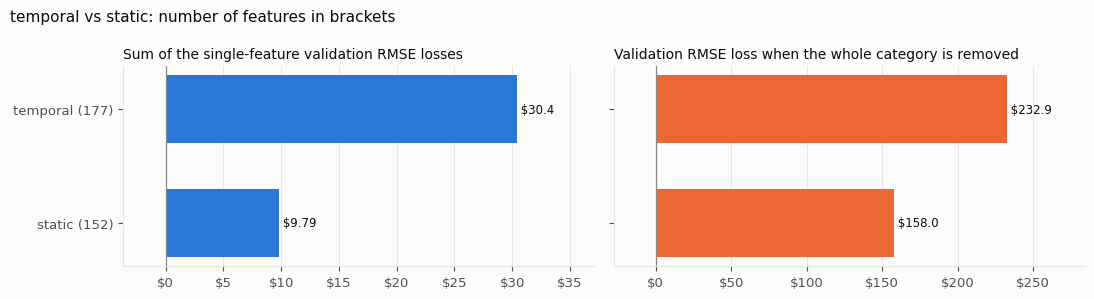

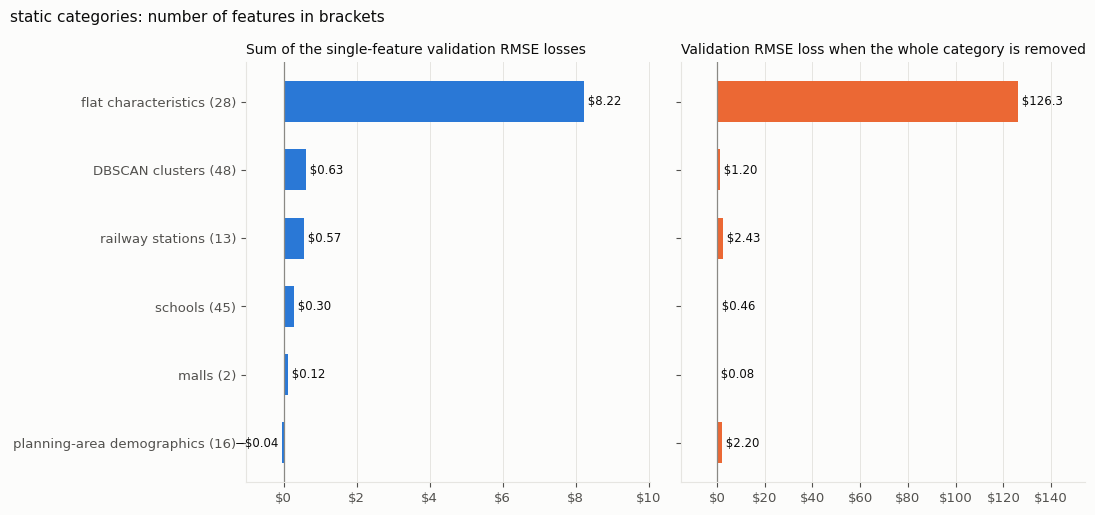

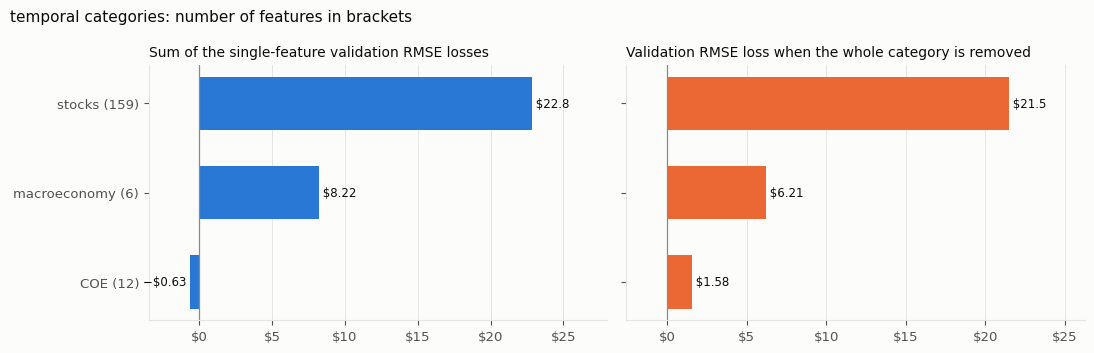

In [8]:
BLUE, ORANGE = '#2a78d6', '#eb6834'
for split in SPLITS:
    part = by_category[by_category['split'] == split].sort_values('sum_val_rmse_loss', ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * len(part) + 1.9))
    pos = np.arange(len(part))
    labels = [f'{c} ({n})' for c, n in zip(part['category'], part['features'])]
    for ax, column, colour, title in ((axes[0], 'sum_val_rmse_loss', BLUE, 'Sum of the single-feature validation RMSE losses'),
                                      (axes[1], 'category_removed_val_rmse_loss', ORANGE, 'Validation RMSE loss when the whole category is removed')):
        ax.barh(pos, part[column], color=colour, height=0.6)
        ax.axvline(0, color='#8a8984', lw=0.9)
        for i, v in enumerate(part[column]):
            text = f'${abs(v):,.2f}' if abs(v) < 10 else f'${abs(v):,.1f}'
            ax.text(v, i, f' {text}' if v >= 0 else f'−{text} ', va='center', ha='left' if v >= 0 else 'right', fontsize=8.5)
        ax.set_yticks(pos, labels if ax is axes[0] else [''] * len(part))
        ax.invert_yaxis()
        ax.grid(axis='y', visible=False)
        lo, hi = min(0, part[column].min()), max(0, part[column].max())
        ax.set_xlim(lo - 0.12 * (hi - lo), hi + 0.22 * (hi - lo))
        ax.xaxis.set_major_formatter('${x:,.0f}')
        ax.set_title(title, fontsize=10)
    fig.suptitle(f'{split}: number of features in brackets', x=0.01, ha='left', fontsize=11)
    plt.tight_layout()
    plt.show()

* **Temporal against static.** The sums of the single-feature losses are $30.4 for the 177 temporal features and $9.8 for the 152 static ones, which taken alone would say that the temporal module matters three times more. But removing a whole module costs $232.9 (temporal) and $158.0 (static): the sums understate both by a factor of 8 to 16, because the features inside a module replace one another.
  Both modules are indispensable. Without the temporal features the model has no information about the month (validation RMSE $735.7, the train RMSE rises by $149.8); without the static features it can only predict the monthly level, and its RMSE ($660.8) is the spread of rents inside a month.
* **Static categories.** The flat characteristics dominate on both measures: a sum of $8.2 (of $10.2 of positive losses in all the static features) and $126.3 when the 28 features are removed together (the train RMSE rises by $82.5). Every other static category costs $2.4 or less when removed entirely: railway stations $2.43, planning-area demographics $2.20, DBSCAN clusters $1.20, schools $0.46 and malls $0.08.
  The sum ranks the demographics last (-$0.04: removing some of their features helps and others hurts, and they cancel) although removing the whole category costs more than removing the clusters: the sum misses the redundancy. The location categories (clusters, demographics, stations, schools) all say where the flat is, so each is replaceable by the others.
* **Temporal categories.** Stocks have the largest sum ($22.8) and the largest loss when removed together ($21.5), the macroeconomy $8.2 and $6.2, COE -$0.6 and $1.6. The six macroeconomic features have the highest loss per feature of any category ($1.37; $0.14 for the stocks).
  Removing even all 159 stock features costs only $21.5, since the macro and COE features carry the same upward trend, so the three modules substitute for one another; and the train RMSE barely moves when a temporal category is removed (at most $0.37), so these validation losses measure how much the forecast depends on the category (how it extrapolates to the validation months), not information that only that category holds.
* **Which to use.** The loss when a whole category is removed is the one to judge a module by; the sum of the single-feature losses ranks features inside a module, but it understates a module whose features replace one another.

## 6. DBSCAN clusters against the administrative zones

- [Feature ablation study](#feature-ablation-study)
- [1. Data](#1-data)
- [2. Benchmark and ablation](#2-benchmark-and-ablation)
- [3. Feature importance table](#3-feature-importance-table)
- [4. Summary by group of features](#4-summary-by-group-of-features)
- [5. Importance by category of features](#5-importance-by-category-of-features)
- [6. DBSCAN clusters against the administrative zones](#6-dbscan-clusters-against-the-administrative-zones)

Several encodings describe where a flat is. The 47 DBSCAN clusters (plus noise) of the blocks are model features (48 one-hot columns). The administrative zones of the blocks, the 5 **regions**, 31 **planning areas**, 26 **towns** and 156 **subzones**, are **not features**, only identifier columns of the feature table, so their losses cannot be read from the ablation table.
To compare them, each zone is one-hot encoded (centred like the other 0/1 columns, from the levels of the train rows; every validation level also occurs in the train rows) and the same Lasso (`alpha = 0.001`) is fitted with different sets of location encodings. The baseline is **no location encoding at all** (the 329 features without the 48 cluster columns, 281 features):

* **Alone:** the baseline plus one encoding. The *loss alone* of an encoding is the validation RMSE of the baseline minus that of the baseline plus the encoding: what it is worth on its own.
* **On top of the others:** the baseline plus all five encodings, and the same without one encoding. The *loss on top of the others* is the validation RMSE without the encoding minus that with all five: what it adds when the other four are already in the model.

The encodings differ in size (5 to 156 columns); the comparison is between them as they are, so a finer encoding can describe more locations. The result is saved to `result/ablation_location_encodings.csv`.

In [9]:
LOCATION_CSV = RESULT_CSV.parent / 'ablation_location_encodings.csv'
DBSCAN_COLUMNS = [c for c in FEATURES if c.startswith('dbscan_cluster_')]
ZONES = {'region': 'REGION', 'planning area': 'PLANNING_AREA', 'town': 'TOWN', 'subzone': 'SUBZONE'}

if LOCATION_CSV.exists() and not RECOMPUTE:
    location = pd.read_csv(LOCATION_CSV)
    print(f'loaded {len(location)} rows from {LOCATION_CSV}')
else:
    blocks, names, owner = [Z], list(FEATURES), ['feature'] * len(FEATURES)
    for zone, column in ZONES.items():
        levels = sorted(static.loc[fit, column].unique())
        dummies = pd.get_dummies(static[column]).reindex(columns=levels, fill_value=0).astype(float).to_numpy()
        assert dummies[val].sum(axis=1).min() == 1                               # every validation rental has a zone seen in the train rows
        blocks.append(dummies - dummies[fit].mean(axis=0))
        names += [f'{zone}_{level}' for level in levels]
        owner += [zone] * len(levels)
    owner = np.array(owner, dtype=object)                                          # object, so that no label is cut to the width of the shortest string array
    owner[np.isin(names, DBSCAN_COLUMNS)] = 'DBSCAN clusters'
    ZA = np.hstack(blocks)
    ZA_train, ZA_val = ZA[fit], ZA[val]
    gram_all = ZA_train.T @ ZA_train
    encodings = ['DBSCAN clusters', *ZONES]
    base = ~np.isin(owner, encodings)                                              # the features without any location encoding
    assert (owner == 'DBSCAN clusters').sum() == len(DBSCAN_COLUMNS) and base.sum() == len(FEATURES) - len(DBSCAN_COLUMNS)
    setups = {'none': base, **{f'{e} only': base | (owner == e) for e in encodings}, 'all five': np.isin(owner, ['feature', *encodings]),
              **{f'all but {e}': np.isin(owner, ['feature', *encodings]) & (owner != e) for e in encodings}}
    rows = []
    for setup, keep in setups.items():
        model = Lasso(alpha=ALPHA, precompute=gram_all[np.ix_(keep, keep)], fit_intercept=False, max_iter=1_000_000, tol=TOL).fit(ZA_train[:, keep], y_train_std)
        rows.append({'setup': setup, 'columns': int(keep.sum()), 'non_zero_coefficients': int((model.coef_ != 0).sum()),
                     'train_rmse': rmse(y[fit], model.predict(ZA_train[:, keep]) * y_std + y_mean), 'val_rmse': rmse(y[val], model.predict(ZA_val[:, keep]) * y_std + y_mean)})
    columns_of = {e: int((owner == e).sum()) for e in encodings}
    location = pd.DataFrame(rows)
    location['encoding_columns'] = [columns_of.get(s.replace(' only', '').replace('all but ', ''), np.nan) if s not in ('none', 'all five') else np.nan for s in location['setup']]
    location.to_csv(LOCATION_CSV, index=False)
    print(f'saved {len(location)} rows to {LOCATION_CSV}')

display(location.round(2).set_index('setup'))
v, t = location.set_index('setup')['val_rmse'], location.set_index('setup')['train_rmse']
columns_of = location.set_index('setup')['encoding_columns']
ENCODINGS = ['region', 'town', 'planning area', 'DBSCAN clusters', 'subzone']                          # from the fewest to the most columns
encoding_loss = pd.DataFrame([{'encoding': e, 'columns': int(columns_of[f'{e} only']), 'val_rmse_loss_alone': v['none'] - v[f'{e} only'], 'train_rmse_change_alone': t['none'] - t[f'{e} only'],
                               'val_rmse_loss_on_top_of_the_others': v[f'all but {e}'] - v['all five'], 'train_rmse_change_on_top_of_the_others': t[f'all but {e}'] - t['all five']} for e in ENCODINGS])
encoding_loss['val_loss_alone_per_column'] = encoding_loss['val_rmse_loss_alone'] / encoding_loss['columns']
print(f'no location encoding: validation RMSE ${v["none"]:,.2f}; all five encodings: ${v["all five"]:,.2f} (together worth ${v["none"] - v["all five"]:,.2f})')
display(encoding_loss.round(3).set_index('encoding'))

loaded 12 rows from /Users/keltonn/Desktop/Repo/school/CS5228-project/final_report/01_data_processing/03_merge_all_features/result/ablation_location_encodings.csv


,columns,non_zero_coefficients,train_rmse,val_rmse,encoding_columns
setup,,,,,
none,281,77,498.87,503.98,NaN
DBSCAN clusters only,329,91,497.91,502.78,48.0
region only,286,79,498.75,503.95,5.0
planning area only,312,89,497.85,502.64,31.0
town only,307,90,497.85,502.66,26.0
subzone only,437,89,497.80,502.61,156.0
all five,547,110,496.99,501.57,NaN
all but DBSCAN clusters,499,108,497.12,501.71,48.0
all but region,542,111,496.99,501.56,5.0


no location encoding: validation RMSE $503.98; all five encodings: $501.57 (together worth $2.41)


,columns,val_rmse_loss_alone,train_rmse_change_alone,val_rmse_loss_on_top_of_the_others,train_rmse_change_on_top_of_the_others,val_loss_alone_per_column
encoding,,,,,,
region,5,0.030,0.118,-0.006,0.004,0.006
town,26,1.327,1.019,-0.023,0.016,0.051
planning area,31,1.345,1.021,-0.000,-0.000,0.043
DBSCAN clusters,48,1.203,0.961,0.139,0.135,0.025
subzone,156,1.371,1.073,0.895,0.669,0.009


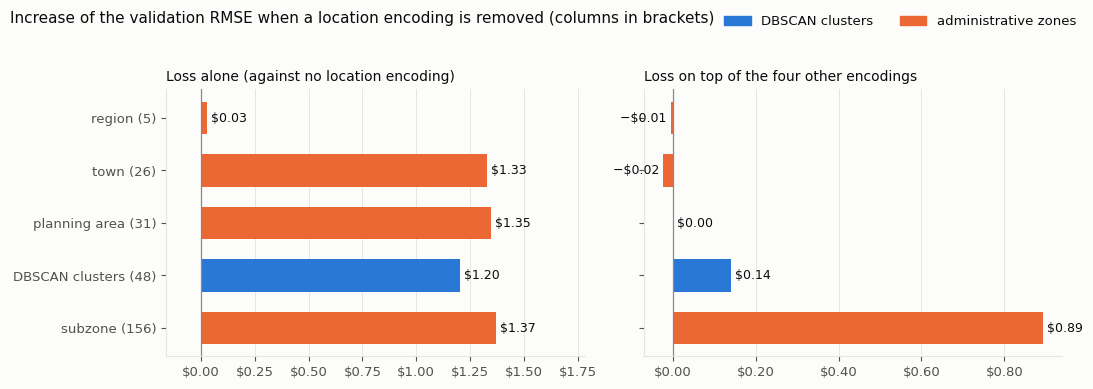

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
colours = ['#2a78d6' if e == 'DBSCAN clusters' else '#eb6834' for e in encoding_loss['encoding']]
for ax, column, title in ((axes[0], 'val_rmse_loss_alone', 'Loss alone (against no location encoding)'), (axes[1], 'val_rmse_loss_on_top_of_the_others', 'Loss on top of the four other encodings')):
    ax.barh(range(len(encoding_loss)), encoding_loss[column], color=colours, height=0.62)
    ax.axvline(0, color='#8a8984', lw=0.9)
    for i, value in enumerate(encoding_loss[column]):
        label = f'${abs(value):,.2f}'
        ax.text(value, i, f' {label}' if value > -0.005 else f'−{label} ', va='center', ha='left' if value > -0.005 else 'right', fontsize=9)
    ax.set_yticks(range(len(encoding_loss)), [f'{e} ({n})' for e, n in zip(encoding_loss['encoding'], encoding_loss['columns'])])
    ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter('${x:,.2f}')
    ax.set_title(title, fontsize=10)
top = max(encoding_loss['val_rmse_loss_alone'].max(), encoding_loss['val_rmse_loss_on_top_of_the_others'].max())
axes[0].set_xlim(min(0, encoding_loss[['val_rmse_loss_alone', 'val_rmse_loss_on_top_of_the_others']].min().min()) - 0.1 * top, top * 1.3)
axes[0].invert_yaxis()                                                          # the y axis is shared: invert it once
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#2a78d6', label='DBSCAN clusters'), plt.Rectangle((0, 0), 1, 1, color='#eb6834', label='administrative zones')], loc='upper right', ncol=2, frameon=False, bbox_to_anchor=(0.99, 1.0))
fig.suptitle('Increase of the validation RMSE when a location encoding is removed (columns in brackets)', x=0.01, ha='left', fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()